## **Objective**
The objective of this notebook is to build a Random Forest Classifier that predicts whether a loan application will be approved or rejected based on applicant, income, credit, loan, and property-related information. In the encoded target column, `0` represents a rejected loan application and `1` represents an approved loan application. The model will be evaluated using classification metrics such as accuracy, precision, recall, F1-score, and ROC-AUC. An appropriate primary evaluation metric should be selected according to the problem statement, class distribution, and the importance of different prediction errors. The selected metric will be used as the scoring measure during hyperparameter tuning and for comparing the baseline and tuned models. Training and testing performance will also be compared using the selected metric to identify possible overfitting. The final model will be selected based on its overall performance and ability to generalise well to unseen data.


## **Import Libraries**
- Import the libraries required for data handling, visualisation, model building, tuning, and evaluation

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, ConfusionMatrixDisplay, confusion_matrix, f1_score, fbeta_score,
                             make_scorer, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate, train_test_split)
%matplotlib inline

RANDOM_STATE = 42
DATA_PATH = Path('../data/Loan_Prediction_data.csv')
FIG_DIR, MET_DIR = Path('../outputs/figures'), Path('../outputs/metrics')
FIG_DIR.mkdir(parents=True, exist_ok=True); MET_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

# **Understanding the Dataset**

## **Task 1**
- Load the loan prediction dataset
- Check the column names and their data types
- Check for missing values

In [2]:
loan_df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
print('Shape:', loan_df.shape)
display(loan_df.head())
print('\nColumn data types:')
print(loan_df.dtypes.to_string())
print('\nMissing values per column:')
print(loan_df.isna().sum().to_string())
print('\nDuplicate rows:', loan_df.duplicated().sum())
display(loan_df.describe().T.round(1))

Shape: (480, 12)


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,Yes,1,Graduate,No,4583,1508.0,128,360,1,Rural,N
1,Male,Yes,0,Graduate,Yes,3000,0.0,66,360,1,Urban,Y
2,Male,Yes,0,Not Graduate,No,2583,2358.0,120,360,1,Urban,Y
3,Male,No,0,Graduate,No,6000,0.0,141,360,1,Urban,Y
4,Male,Yes,2,Graduate,Yes,5417,4196.0,267,360,1,Urban,Y



Column data types:
Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount             int64
Loan_Amount_Term       int64
Credit_History         int64
Property_Area            str
Loan_Status              str

Missing values per column:
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,480.0,5364.2,5668.3,150.0,2898.8,3859.0,5852.5,81000.0
CoapplicantIncome,480.0,1581.1,2617.7,0.0,0.0,1084.5,2253.2,33837.0
LoanAmount,480.0,144.7,80.5,9.0,100.0,128.0,170.0,600.0
Loan_Amount_Term,480.0,342.0,65.2,36.0,360.0,360.0,360.0,480.0
Credit_History,480.0,0.9,0.4,0.0,1.0,1.0,1.0,1.0


## **Task 2**
- Display the count of approved and rejected loan applications using readable labels
- Visualise the number of approved and rejected applications using a bar plot

,Count,Share (%)
Loan_Status,,
Approved,332,69.2
Rejected,148,30.8


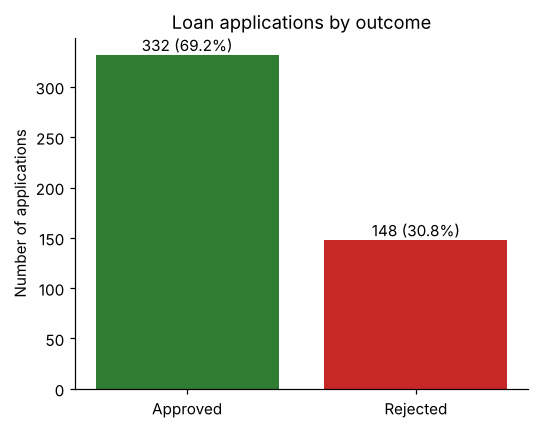

Loan_Status,Approved,Rejected,All
Credit_History,,,
0,7,63,70
1,325,85,410
All,332,148,480


In [3]:
status_labels = loan_df['Loan_Status'].map({'Y': 'Approved', 'N': 'Rejected'})
status_counts = status_labels.value_counts()
status_share = status_labels.value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({'Count': status_counts, 'Share (%)': status_share}))

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(status_counts.index, status_counts.values, color=['#2E7D32', '#C62828'])
ax.bar_label(bars, labels=[f'{c} ({s}%)' for c, s in zip(status_counts, status_share)])
ax.set_title('Loan applications by outcome'); ax.set_ylabel('Number of applications')
plt.tight_layout(); plt.savefig(FIG_DIR / 'class_distribution.png', bbox_inches='tight'); plt.show()

# Approval rate by credit history - the single strongest signal in this dataset
display(pd.crosstab(loan_df['Credit_History'], status_labels, margins=True))

**Observation:** 69.2% of applications are approved and 30.8% rejected, a moderate imbalance. Accuracy alone would flatter a model that approves everyone (69% accuracy for doing nothing). Credit history dominates: applicants without a credit history are approved 10% of the time (7 of 70), against 79% (325 of 410) for those with one.

# **Data Preparation**

## **Task 3**
- Convert the target labels into numerical values

In [4]:
loan_df['Loan_Status'] = loan_df['Loan_Status'].map({'N': 0, 'Y': 1})
print(loan_df['Loan_Status'].value_counts().rename({0: '0 = Rejected', 1: '1 = Approved'}))

Loan_Status
1 = Approved    332
0 = Rejected    148
Name: count, dtype: int64


## **Task 4**
- Separate the predictor features and target variable
- Create stratified training and testing sets

In [5]:
X = loan_df.drop(columns='Loan_Status')
y = loan_df['Loan_Status']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

In [6]:
print('Training set:', X_train.shape, '| Testing set:', X_test.shape)
print('Approval rate - train: {:.3f} | test: {:.3f}'.format(y_train.mean(), y_test.mean()))

Training set: (384, 11) | Testing set: (96, 11)
Approval rate - train: 0.693 | test: 0.688


## **Task 5**
- Encode the categorical training and testing features 

In [7]:
def encode_features(df, reference_columns=None):
    """Binary columns -> 0/1, Dependents -> ordinal integer, Property_Area -> one-hot.
    Test data is re-indexed to the training columns so both sets share one schema."""
    out = df.copy()
    out['Gender'] = (out['Gender'] == 'Male').astype(int)
    out['Married'] = (out['Married'] == 'Yes').astype(int)
    out['Education'] = (out['Education'] == 'Graduate').astype(int)
    out['Self_Employed'] = (out['Self_Employed'] == 'Yes').astype(int)
    out['Dependents'] = out['Dependents'].replace('3+', '3').astype(int)
    out = pd.get_dummies(out, columns=['Property_Area'], prefix='Area', dtype=int)
    if reference_columns is not None:
        out = out.reindex(columns=reference_columns, fill_value=0)
    return out

X_train_enc = encode_features(X_train)
X_test_enc = encode_features(X_test, reference_columns=X_train_enc.columns)
print('Encoded feature count:', X_train_enc.shape[1])
display(X_train_enc.head())

Encoded feature count: 13


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Area_Rural,Area_Semiurban,Area_Urban
370,1,1,2,1,1,16525,1014.0,150,360,1,1,0,0
356,1,1,0,1,0,4301,0.0,118,360,1,0,0,1
265,1,1,1,0,0,4554,1229.0,158,360,1,0,0,1
344,1,0,0,1,0,3660,5064.0,187,360,1,0,1,0
195,1,1,0,0,0,1668,3890.0,201,360,0,0,1,0


# **Model Training**

## **Task 6**
- Train the baseline Random Forest model
- Generate training and testing predictions
- Evaluate the baseline model using confusion matrices, accuracy, precision, recall, F1-score, and ROC-AUC

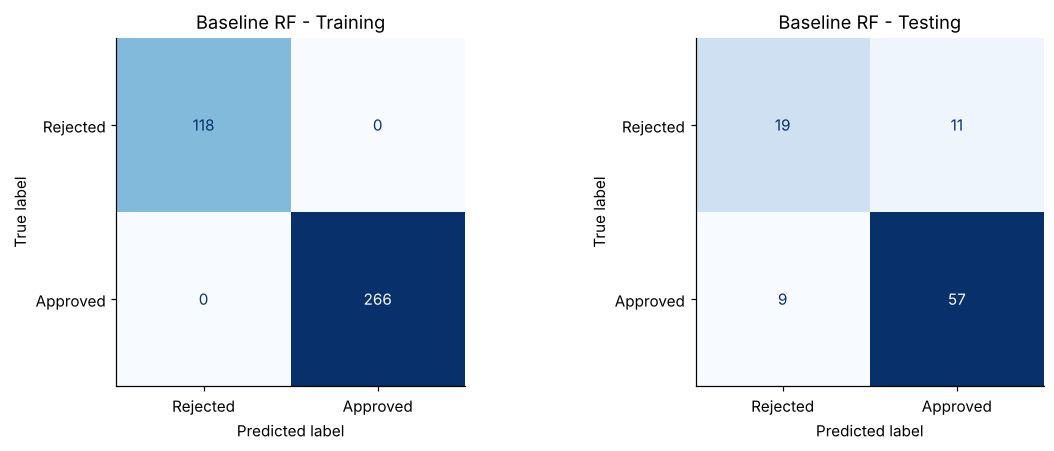

,Training,Testing
Accuracy,1.0,0.792
Precision,1.0,0.838
Recall,1.0,0.864
F1,1.0,0.851
F0.5,1.0,0.843
Specificity,1.0,0.633
ROC-AUC,1.0,0.801


In [8]:
def evaluate(y_true, y_pred, y_prob):
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'F1': f1_score(y_true, y_pred),
            'F0.5': fbeta_score(y_true, y_pred, beta=0.5),
            'Specificity': recall_score(y_true, y_pred, pos_label=0),
            'ROC-AUC': roc_auc_score(y_true, y_prob)}

def plot_confusion_pair(model_name, train_pred, test_pred, filename):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, (split, yt, yp) in zip(axes, [('Training', y_train, train_pred), ('Testing', y_test, test_pred)]):
        ConfusionMatrixDisplay(confusion_matrix(yt, yp), display_labels=['Rejected', 'Approved']).plot(
            ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(f'{model_name} - {split}')
    plt.tight_layout(); plt.savefig(FIG_DIR / filename, bbox_inches='tight'); plt.show()

baseline_rf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
baseline_rf.fit(X_train_enc, y_train)

base_train_pred = baseline_rf.predict(X_train_enc)
base_test_pred = baseline_rf.predict(X_test_enc)
base_train_prob = baseline_rf.predict_proba(X_train_enc)[:, 1]
base_test_prob = baseline_rf.predict_proba(X_test_enc)[:, 1]

plot_confusion_pair('Baseline RF', base_train_pred, base_test_pred, 'confusion_baseline.png')
base_metrics = pd.DataFrame({'Training': evaluate(y_train, base_train_pred, base_train_prob),
                             'Testing': evaluate(y_test, base_test_pred, base_test_prob)}).round(3)
display(base_metrics)

## **Task 7**
- Find the parameters used by the baseline Random Forest model
- Compare the training and testing values of the selected evaluation metric and calculate the performance gap to check for possible overfitting

In [9]:
print('Baseline Random Forest parameters:')
print(pd.Series(baseline_rf.get_params()).to_string())

# Primary metric: F0.5 on the "Approved" class.
# Approving an applicant who should have been rejected (false positive) is the costlier error for a
# lender, so precision is weighted twice as heavily as recall, while recall still prevents the
# degenerate "reject everyone" solution. F1 and ROC-AUC are reported alongside for transparency.
PRIMARY = 'F0.5'
base_gap = base_metrics.loc[PRIMARY, 'Training'] - base_metrics.loc[PRIMARY, 'Testing']
print(f'\nBaseline {PRIMARY}: train = {base_metrics.loc[PRIMARY, "Training"]:.3f}, '
      f'test = {base_metrics.loc[PRIMARY, "Testing"]:.3f}, gap = {base_gap:.3f}')

Baseline Random Forest parameters:
bootstrap                    True
ccp_alpha                     0.0
class_weight                 None
criterion                    gini
max_depth                    None
max_features                 sqrt
max_leaf_nodes               None
max_samples                  None
min_impurity_decrease         0.0
min_samples_leaf                1
min_samples_split               2
min_weight_fraction_leaf      0.0
monotonic_cst                None
n_estimators                  100
n_jobs                         -1
oob_score                   False
random_state                   42
verbose                         0
warm_start                  False

Baseline F0.5: train = 1.000, test = 0.843, gap = 0.157


**Observation:** The baseline forest grows fully deep trees (`max_depth=None`, `min_samples_leaf=1`) and reproduces the training set perfectly: train F0.5 = 1.000 against test F0.5 = 0.843, a gap of 0.157. It has memorised the training data rather than learning a general rule.

## **Task 8**
- Display sample loan applications with their actual and baseline predicted labels

In [10]:
label_map = {0: 'Rejected', 1: 'Approved'}
sample_idx = X_test.sample(8, random_state=RANDOM_STATE).index
base_samples = X_test.loc[sample_idx, ['Married', 'Education', 'ApplicantIncome', 'CoapplicantIncome',
                                       'LoanAmount', 'Credit_History', 'Property_Area']].copy()
base_samples['Actual'] = y_test.loc[sample_idx].map(label_map)
base_samples['Baseline Predicted'] = pd.Series(base_test_pred, index=X_test.index).loc[sample_idx].map(label_map)
base_samples['P(Approved)'] = pd.Series(base_test_prob, index=X_test.index).loc[sample_idx].round(2)
display(base_samples)

,Married,Education,ApplicantIncome,CoapplicantIncome,LoanAmount,Credit_History,Property_Area,Actual,Baseline Predicted,P(Approved)
340,No,Graduate,3750,0.0,100,1,Urban,Approved,Rejected,0.46
286,Yes,Graduate,19730,5266.0,570,1,Rural,Rejected,Rejected,0.39
6,Yes,Graduate,3036,2504.0,158,0,Semiurban,Rejected,Rejected,0.28
192,Yes,Not Graduate,6608,0.0,137,1,Urban,Approved,Approved,0.82
322,Yes,Not Graduate,2253,2033.0,110,1,Rural,Approved,Approved,0.88
327,Yes,Graduate,1025,2773.0,112,1,Rural,Approved,Approved,0.52
288,Yes,Graduate,5185,0.0,155,1,Semiurban,Approved,Approved,0.89
338,No,Graduate,6500,0.0,105,0,Rural,Rejected,Rejected,0.28


## **Task 9**
- Display the top five most important features of the baseline Random Forest model

,Impurity importance
Credit_History,0.212
ApplicantIncome,0.207
LoanAmount,0.193
CoapplicantIncome,0.110
Dependents,0.056


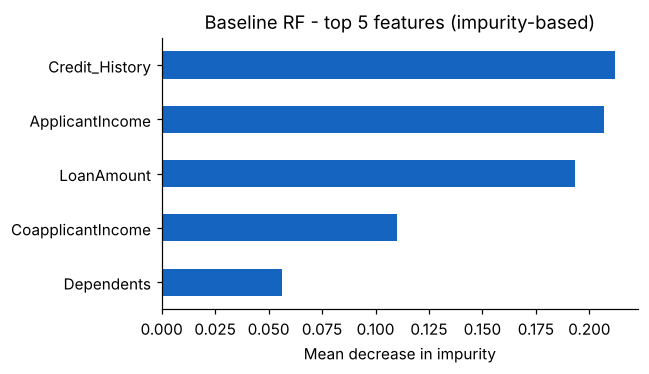

In [11]:
base_importance = pd.Series(baseline_rf.feature_importances_, index=X_train_enc.columns).sort_values(ascending=False)
display(base_importance.head(5).round(3).to_frame('Impurity importance'))

fig, ax = plt.subplots(figsize=(6, 3.5))
base_importance.head(5)[::-1].plot.barh(ax=ax, color='#1565C0')
ax.set_title('Baseline RF - top 5 features (impurity-based)'); ax.set_xlabel('Mean decrease in impurity')
plt.tight_layout(); plt.savefig(FIG_DIR / 'feature_importance_baseline.png', bbox_inches='tight'); plt.show()

**Observation:** Impurity-based importance ranks Credit_History (0.212), ApplicantIncome (0.207) and LoanAmount (0.193) close together. That ranking is computed on training data, and impurity importance is known to favour continuous features with many split points. Extension D tests whether income and loan amount still matter on unseen data.

# **Hyperparameter Tuning**

## **Task 10**
- Define suitable values for `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, and `class_weight` that will be tested during Random Forest hyperparameter tuning

In [12]:
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [3, 5, 8, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10],
    'class_weight': [None, 'balanced'],
}
n_combos = int(np.prod([len(v) for v in param_grid.values()]))
print(f'{n_combos} combinations x 5 folds = {n_combos * 5} fits')

144 combinations x 5 folds = 720 fits


## **Task 11**
- Select an appropriate scoring metric according to the problem statement and model objective
- Tune the Random Forest model using five-fold cross-validation and the selected scoring metric
- Display the best hyperparameters, best cross-validation score, and best trained model selected by GridSearchCV

In [13]:
f05_scorer = make_scorer(fbeta_score, beta=0.5)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                    param_grid=param_grid, scoring=f05_scorer, cv=cv5, n_jobs=-1, refit=True)
grid.fit(X_train_enc, y_train)

print('Best hyperparameters:', grid.best_params_)
print(f'Best 5-fold CV {PRIMARY}: {grid.best_score_:.3f}')
print('Best model:', grid.best_estimator_)

cv_res = pd.DataFrame(grid.cv_results_).sort_values('rank_test_score').head(5)
cv_table = pd.concat([pd.DataFrame(cv_res['params'].tolist()),
                      cv_res[['mean_test_score', 'std_test_score']].reset_index(drop=True)], axis=1)
cv_table.columns = [c.replace('mean_test_score', 'CV F0.5 mean').replace('std_test_score', 'CV F0.5 std') for c in cv_table.columns]
display(cv_table.round(3))

Best hyperparameters: {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 100}
Best 5-fold CV F0.5: 0.825
Best model: RandomForestClassifier(min_samples_split=10, n_jobs=-1, random_state=42)


,class_weight,max_depth,min_samples_leaf,min_samples_split,n_estimators,CV F0.5 mean,CV F0.5 std
0,NaN,NaN,1,10,100,0.825,0.030
1,NaN,NaN,1,20,100,0.824,0.024
2,balanced,5.0,1,2,100,0.824,0.033
3,NaN,8.0,5,20,300,0.823,0.022
4,NaN,NaN,5,2,300,0.823,0.022


**Observation:** The best configuration changes only `min_samples_split` (2 to 10) and keeps the other defaults, giving CV F0.5 = 0.825. The top five configurations sit within 0.002 of each other, well inside the fold-to-fold standard deviation of about 0.03. The tuning surface is flat, so the choice between these configurations is not meaningful.

# **Tuned Model Evaluation and Interpretation**

## **Task 12**
- Store the best tuned Random Forest model and generate predictions and probability scores for the training and testing datasets
- Calculate the training and testing performance gap using the selected evaluation metric

In [14]:
tuned_rf = grid.best_estimator_
tuned_train_pred = tuned_rf.predict(X_train_enc)
tuned_test_pred = tuned_rf.predict(X_test_enc)
tuned_train_prob = tuned_rf.predict_proba(X_train_enc)[:, 1]
tuned_test_prob = tuned_rf.predict_proba(X_test_enc)[:, 1]

tuned_metrics = pd.DataFrame({'Training': evaluate(y_train, tuned_train_pred, tuned_train_prob),
                              'Testing': evaluate(y_test, tuned_test_pred, tuned_test_prob)}).round(3)
tuned_gap = tuned_metrics.loc[PRIMARY, 'Training'] - tuned_metrics.loc[PRIMARY, 'Testing']
print(f'Tuned {PRIMARY}: train = {tuned_metrics.loc[PRIMARY, "Training"]:.3f}, '
      f'test = {tuned_metrics.loc[PRIMARY, "Testing"]:.3f}, gap = {tuned_gap:.3f}')

Tuned F0.5: train = 0.888, test = 0.857, gap = 0.031


**Observation:** Tuning cuts the train-test F0.5 gap from 0.157 to 0.031 (train 0.888, test 0.857). Requiring at least 10 samples before a split stops individual trees from isolating single applicants.

## **Task 13**
- Display sample loan applications with their actual and tuned-model predicted labels

In [15]:
tuned_samples = base_samples.drop(columns=['Baseline Predicted', 'P(Approved)']).copy()
tuned_samples['Tuned Predicted'] = pd.Series(tuned_test_pred, index=X_test.index).loc[sample_idx].map(label_map)
tuned_samples['P(Approved)'] = pd.Series(tuned_test_prob, index=X_test.index).loc[sample_idx].round(2)
display(tuned_samples)

,Married,Education,ApplicantIncome,CoapplicantIncome,LoanAmount,Credit_History,Property_Area,Actual,Tuned Predicted,P(Approved)
340,No,Graduate,3750,0.0,100,1,Urban,Approved,Approved,0.62
286,Yes,Graduate,19730,5266.0,570,1,Rural,Rejected,Rejected,0.37
6,Yes,Graduate,3036,2504.0,158,0,Semiurban,Rejected,Rejected,0.26
192,Yes,Not Graduate,6608,0.0,137,1,Urban,Approved,Approved,0.79
322,Yes,Not Graduate,2253,2033.0,110,1,Rural,Approved,Approved,0.82
327,Yes,Graduate,1025,2773.0,112,1,Rural,Approved,Approved,0.50
288,Yes,Graduate,5185,0.0,155,1,Semiurban,Approved,Approved,0.86
338,No,Graduate,6500,0.0,105,0,Rural,Rejected,Rejected,0.26


## **Task 14**
- Create confusion matrices to compare the actual and predicted classes for the tuned model’s training and testing sets

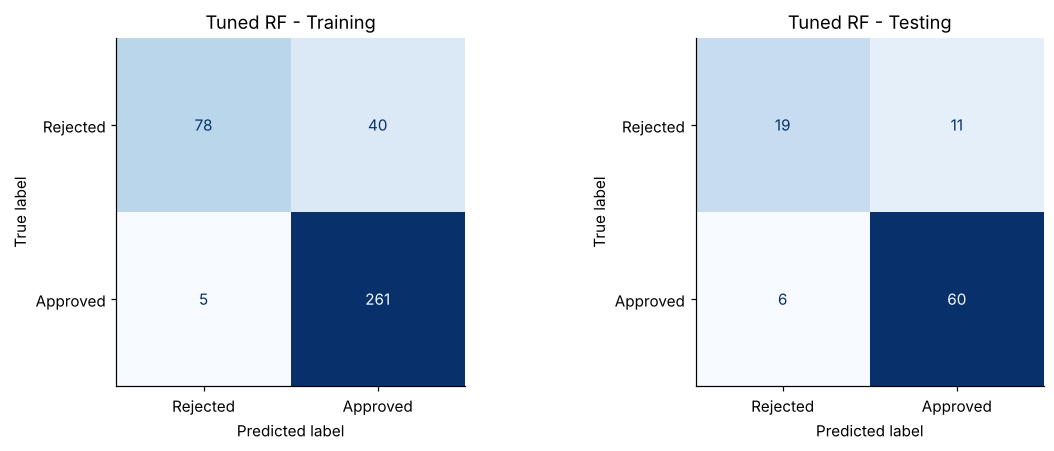

In [16]:
plot_confusion_pair('Tuned RF', tuned_train_pred, tuned_test_pred, 'confusion_tuned.png')

## **Task 15**
- Evaluate the tuned Random Forest model using accuracy, precision, recall, F1-score, and ROC-AUC

In [17]:
display(tuned_metrics)

,Training,Testing
Accuracy,0.883,0.823
Precision,0.867,0.845
Recall,0.981,0.909
F1,0.921,0.876
F0.5,0.888,0.857
Specificity,0.661,0.633
ROC-AUC,0.980,0.795


**Observation:** On the 96 test applications (66 approved, 30 rejected), the tuned model's approval decisions are right 84.5% of the time (precision), and it approves 90.9% of genuinely approvable applicants (recall). Specificity is the weak point: it catches 19 of the 30 applications that should be rejected (0.633) and approves the other 11.

## **Task 16**
- Plot the training and testing ROC curves for the baseline and tuned models

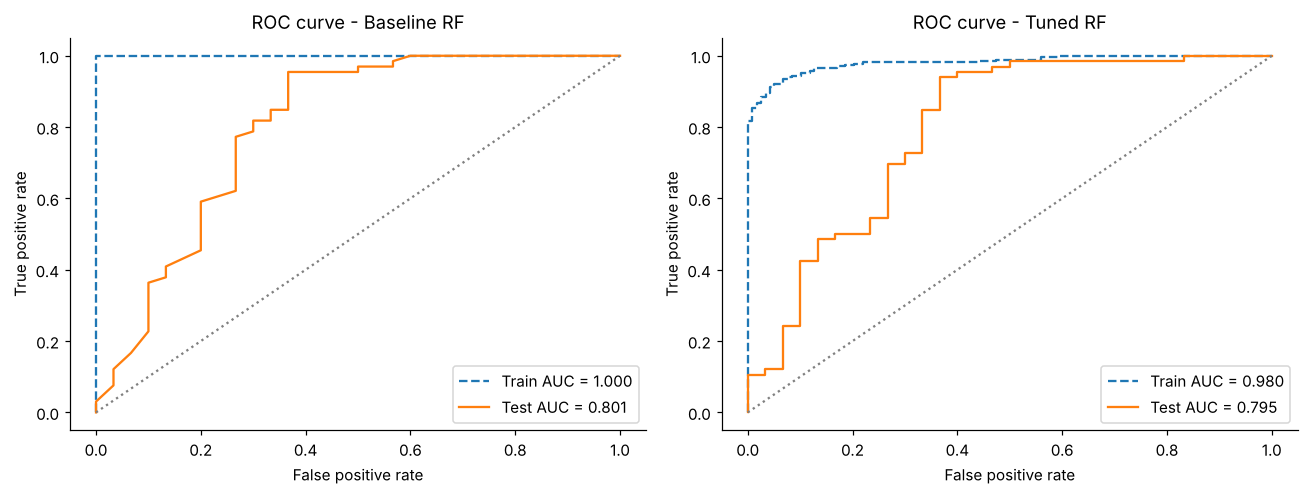

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (name, tr_p, te_p) in zip(axes, [('Baseline RF', base_train_prob, base_test_prob),
                                         ('Tuned RF', tuned_train_prob, tuned_test_prob)]):
    for split, yt, pp, ls in [('Train', y_train, tr_p, '--'), ('Test', y_test, te_p, '-')]:
        fpr, tpr, _ = roc_curve(yt, pp)
        ax.plot(fpr, tpr, ls, label=f'{split} AUC = {roc_auc_score(yt, pp):.3f}')
    ax.plot([0, 1], [0, 1], ':', color='grey'); ax.set_title(f'ROC curve - {name}')
    ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(FIG_DIR / 'roc_curves.png', bbox_inches='tight'); plt.show()

**Observation:** Both models still separate the classes far better on training data (AUC 1.000 and 0.980) than on test data (0.801 and 0.795). Tuning closed the gap in hard predictions, but the probability ranking still overfits. Test AUC barely changes with tuning.

## **Task 17**
- Compare accuracy, precision, recall, F1-score, and ROC-AUC for the baseline and tuned Random Forest models and also compare the training and testing performance gaps using the selected primary evaluation metric

In [19]:
comparison = pd.DataFrame({
    'Baseline - Train': base_metrics['Training'], 'Baseline - Test': base_metrics['Testing'],
    'Tuned - Train': tuned_metrics['Training'], 'Tuned - Test': tuned_metrics['Testing']})
comparison.loc[f'{PRIMARY} train-test gap'] = [base_gap, np.nan, tuned_gap, np.nan]
display(comparison.round(3))
comparison.round(4).to_csv(MET_DIR / 'baseline_vs_tuned.csv')

,Baseline - Train,Baseline - Test,Tuned - Train,Tuned - Test
Accuracy,1.000,0.792,0.883,0.823
Precision,1.000,0.838,0.867,0.845
Recall,1.000,0.864,0.981,0.909
F1,1.000,0.851,0.921,0.876
F0.5,1.000,0.843,0.888,0.857
Specificity,1.000,0.633,0.661,0.633
ROC-AUC,1.000,0.801,0.980,0.795
F0.5 train-test gap,0.157,NaN,0.031,NaN


**Observation:** Tuning improves every test metric that depends on hard predictions (accuracy 0.792 to 0.823, F0.5 0.843 to 0.857, F1 0.851 to 0.876) and shrinks the overfitting gap fivefold. Test ROC-AUC does not improve (0.801 to 0.795). With 96 test rows, one misclassification moves accuracy by about 1 percentage point, so Extension B checks whether these gains hold up.

# **Extensions Beyond the Exercise**
The tasks above answer *"does tuning help?"*. The cells below answer the questions a credit-risk reviewer would ask next:
1. Does the model beat a one-line credit-history rule?
2. How stable is the result across different data splits (the test set has only 96 rows)?
3. What does the decision threshold trade off?
4. Which features matter when importance is measured on unseen data?

## **Extension A - One-rule benchmark**
Rule: *approve if `Credit_History == 1`, otherwise reject.* Any model worth deploying has to beat this.

In [20]:
rule_test_pred = X_test['Credit_History'].astype(int).values
rule_metrics = evaluate(y_test, rule_test_pred, rule_test_pred)
benchmark = pd.DataFrame({'Credit-history rule': rule_metrics,
                          'Baseline RF': base_metrics['Testing'], 'Tuned RF': tuned_metrics['Testing']}).round(3)
display(benchmark)
benchmark.to_csv(MET_DIR / 'test_benchmark_vs_rule.csv')

,Credit-history rule,Baseline RF,Tuned RF
Accuracy,0.833,0.792,0.823
Precision,0.821,0.838,0.845
Recall,0.970,0.864,0.909
F1,0.889,0.851,0.876
F0.5,0.847,0.843,0.857
Specificity,0.533,0.633,0.633
ROC-AUC,0.752,0.801,0.795


**Observation:** On this test split, the one-line rule scores higher accuracy (0.833 vs 0.823) and F1 (0.889 vs 0.876) than the tuned forest, and a slightly lower F0.5 (0.847 vs 0.857). The forest's advantage is specificity: it rejects 19 of the 30 bad applications against the rule's 16. It pays for that by turning away 4 more good applicants.

## **Extension B - Stability under repeated cross-validation**
A 96-row test set moves by about 1 percentage point per misclassified application. Repeated stratified 5-fold CV (10 repeats, 50 fits) on the full dataset gives a mean and spread instead of a single number. The tuned hyperparameters are held fixed.

In [21]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
X_all_enc = encode_features(X, reference_columns=X_train_enc.columns)
scoring = {'F0.5': f05_scorer, 'F1': 'f1', 'Accuracy': 'accuracy', 'ROC-AUC': 'roc_auc'}

def cv_summary(model, Xm):
    res = cross_validate(model, Xm, y, cv=rcv, scoring=scoring, n_jobs=-1)
    return {k: f"{res['test_' + k].mean():.3f} +/- {res['test_' + k].std():.3f}" for k in scoring}

stability = pd.DataFrame({
    'Baseline RF': cv_summary(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), X_all_enc),
    'Tuned RF': cv_summary(RandomForestClassifier(**{**tuned_rf.get_params(), 'n_jobs': -1}), X_all_enc)})

rule_scores = {k: [] for k in scoring}
for tr, te in rcv.split(X_all_enc, y):
    yp = X_all_enc.iloc[te]['Credit_History'].values; yt = y.iloc[te]
    rule_scores['F0.5'].append(fbeta_score(yt, yp, beta=0.5)); rule_scores['F1'].append(f1_score(yt, yp))
    rule_scores['Accuracy'].append(accuracy_score(yt, yp)); rule_scores['ROC-AUC'].append(roc_auc_score(yt, yp))
stability['Credit-history rule'] = {k: f'{np.mean(v):.3f} +/- {np.std(v):.3f}' for k, v in rule_scores.items()}
display(stability)
stability.to_csv(MET_DIR / 'repeated_cv_stability.csv')

,Baseline RF,Tuned RF,Credit-history rule
F0.5,0.823 +/- 0.027,0.827 +/- 0.028,0.825 +/- 0.025
F1,0.858 +/- 0.025,0.872 +/- 0.021,0.876 +/- 0.019
Accuracy,0.788 +/- 0.037,0.804 +/- 0.035,0.808 +/- 0.032
ROC-AUC,0.759 +/- 0.064,0.764 +/- 0.058,0.702 +/- 0.049


**Observation:** Across 50 resamples, the tuned forest and the credit-history rule are statistically indistinguishable on F0.5 (0.827 vs 0.825, std ~0.03), F1 and accuracy. The forest's consistent edge is ROC-AUC (0.764 vs 0.702): it ranks applicants better, which a binary rule cannot do. Tuning adds little over the baseline forest once the variance from single splits is removed.

## **Extension C - Decision-threshold trade-off**
The default threshold of 0.5 is arbitrary. Out-of-fold probabilities on the **training set only** (the test set stays untouched) show how precision, recall and specificity move as the approval threshold rises.

,Precision,Recall,Specificity,F0.5,Approval rate
Threshold,,,,,
0.30,0.772,0.981,0.347,0.807,0.880
0.35,0.786,0.981,0.398,0.819,0.865
0.40,0.789,0.981,0.407,0.821,0.862
0.45,0.792,0.974,0.424,0.823,0.852
0.50,0.797,0.959,0.449,0.825,0.833
0.55,0.800,0.932,0.475,0.823,0.807
0.60,0.801,0.891,0.500,0.817,0.771
0.65,0.812,0.812,0.576,0.812,0.693
0.70,0.824,0.722,0.653,0.801,0.607


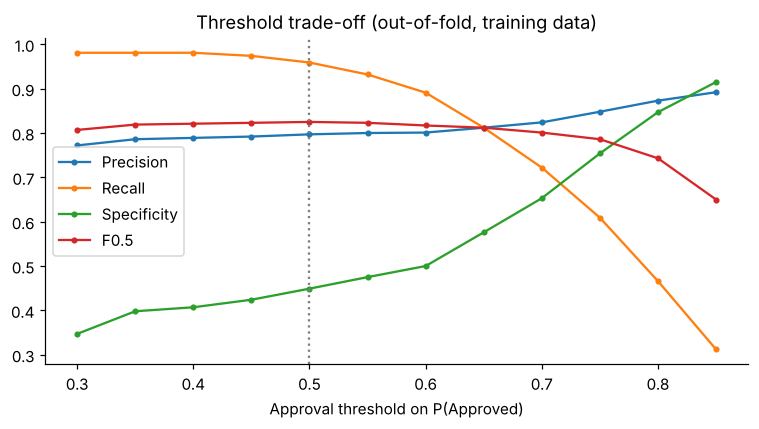

In [22]:
oof_prob = cross_val_predict(RandomForestClassifier(**{**tuned_rf.get_params(), 'n_jobs': -1}),
                             X_train_enc, y_train, cv=cv5, method='predict_proba')[:, 1]
thresholds = np.round(np.arange(0.30, 0.86, 0.05), 2)
rows = []
for t in thresholds:
    p = (oof_prob >= t).astype(int)
    rows.append({'Threshold': t, 'Precision': precision_score(y_train, p, zero_division=0),
                 'Recall': recall_score(y_train, p), 'Specificity': recall_score(y_train, p, pos_label=0),
                 'F0.5': fbeta_score(y_train, p, beta=0.5), 'Approval rate': p.mean()})
thr_df = pd.DataFrame(rows).set_index('Threshold').round(3)
display(thr_df)
thr_df.to_csv(MET_DIR / 'threshold_tradeoff_oof.csv')

fig, ax = plt.subplots(figsize=(7, 4))
for col in ['Precision', 'Recall', 'Specificity', 'F0.5']:
    ax.plot(thr_df.index, thr_df[col], marker='o', ms=3, label=col)
ax.axvline(0.5, color='grey', ls=':'); ax.set_xlabel('Approval threshold on P(Approved)')
ax.set_title('Threshold trade-off (out-of-fold, training data)'); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'threshold_tradeoff.png', bbox_inches='tight'); plt.show()

**Observation:** The threshold has a much larger effect than any hyperparameter. At 0.50 the model approves 83% of training applicants with specificity 0.449. Raising the threshold to 0.75 lifts precision to 0.848 and specificity to 0.754, but approves only half the applicants and drops recall to 0.609. Where to set it is a credit-policy decision about the cost of a bad loan versus a lost good customer, not a modelling decision.

## **Extension D - Permutation importance on the test set**
Impurity-based importance is computed on training data and inflates continuous, high-cardinality features such as income. Permutation importance measures how much test-set ROC-AUC drops when one feature is shuffled.

,Permutation (test AUC drop),Std,"Impurity (tuned, train)"
Credit_History,0.2906,0.0467,0.3289
Education,0.0126,0.0071,0.0224
Loan_Amount_Term,0.0034,0.0094,0.0588
Self_Employed,0.0004,0.0038,0.0146
Area_Rural,-0.0000,0.0084,0.0227
ApplicantIncome,-0.0015,0.0172,0.1679
Area_Semiurban,-0.0028,0.0133,0.0305
Dependents,-0.0040,0.0070,0.0320
Area_Urban,-0.0042,0.0039,0.0124
CoapplicantIncome,-0.0050,0.0104,0.1013


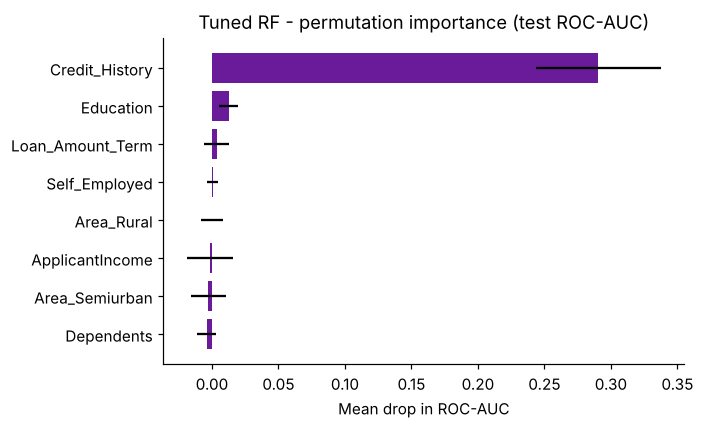

In [23]:
perm = permutation_importance(tuned_rf, X_test_enc, y_test, scoring='roc_auc', n_repeats=30,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_df = (pd.DataFrame({'Permutation (test AUC drop)': perm.importances_mean, 'Std': perm.importances_std,
                         'Impurity (tuned, train)': tuned_rf.feature_importances_}, index=X_test_enc.columns)
           .sort_values('Permutation (test AUC drop)', ascending=False).round(4))
display(perm_df)
perm_df.to_csv(MET_DIR / 'feature_importance_permutation_vs_impurity.csv')

top = perm_df.head(8)[::-1]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(top.index, top['Permutation (test AUC drop)'], xerr=top['Std'], color='#6A1B9A')
ax.set_title('Tuned RF - permutation importance (test ROC-AUC)'); ax.set_xlabel('Mean drop in ROC-AUC')
plt.tight_layout(); plt.savefig(FIG_DIR / 'permutation_importance.png', bbox_inches='tight'); plt.show()

**Observation:** Measured on unseen data, Credit_History is the only feature with a clear effect: shuffling it drops test ROC-AUC by 0.29. Every other feature's mean effect is within one standard deviation of zero. ApplicantIncome and LoanAmount, ranked 2nd and 3rd by impurity importance, contribute nothing measurable on the test set, which confirms the impurity bias flagged in Task 9.

# **Conclusion**

| Question | Answer |
|---|---|
| Does tuning help? | Yes for overfitting (F0.5 gap 0.157 to 0.031) and hard-prediction metrics on this split. Under repeated CV the gain over the baseline forest is small. |
| Does the model beat a one-line rule? | Not on F0.5, F1 or accuracy (statistically tied). It does rank applicants better (ROC-AUC 0.764 vs 0.702) and rejects more bad applications at the default threshold. |
| What drives predictions? | Credit history. No other feature shows a measurable effect on unseen data. |
| What is the model useful for? | A calibratable **risk score**: the threshold can be set to a lender's risk appetite, which a yes/no rule cannot offer. |

**Limitations:** 480 rows, with 96 in the test set. The dataset appears to be a complete-case subset of the public Loan Prediction data, so dropping rows with missing values may introduce selection bias. Gender and marital status are used as features: they add nothing measurable here, but a production lending model would need a fair-lending review before using them. Probabilities have not been calibrated.